In [5]:
import numpy as np
from scipy.optimize import root
import matplotlib.pyplot as plt

# 1. Parámetros del sistema Sol-Júpiter
mu = 0.00095378
x1, x2 = -mu, 1 - mu  # Posiciones de Sol y Júpiter


def grad_U_eff(pos):
    """Calcula el gradiente del potencial efectivo en el plano xy (z=0).

    pos: array-like [x, y]
    Retorna: [dU/dx, dU/dy]
    """
    x, y = pos

    # Distancias a los primarios
    r1 = np.sqrt((x - x1) ** 2 + y**2)
    r2 = np.sqrt((x - x2) ** 2 + y**2)

    # Componentes del gradiente (adimensionales)
    dU_dx = (1 - mu) * (x - x1) / r1**3 + mu * (x - x2) / r2**3 - x
    dU_dy = y * ((1 - mu) / r1**3 + mu / r2**3 - 1)

    return np.array([dU_dx, dU_dy])


# 2. Estimaciones iniciales teóricas para cada punto [x, y]
rho_L1_L2 = (mu / 3) ** (1 / 3)

initial_guesses = {
    "L1": [x2 - rho_L1_L2, 0.0],  # Entre el Sol y Júpiter
    "L2": [x2 + rho_L1_L2, 0.0],  # Más allá de Júpiter
    "L3": [-1.0 - (7 / 12) * mu, 0.0],  # Detrás del Sol
    "L4": [0.5 - mu, np.sqrt(3) / 2],  # Vértice superior del triángulo
    "L5": [0.5 - mu, -np.sqrt(3) / 2],  # Vértice inferior del triángulo
}

# 3. Resolver el sistema para cada estimación inicial
lagrange_points = {}

for name, guess in initial_guesses.items():
    sol = root(grad_U_eff, guess, method="hybr")
    if sol.success:
        lagrange_points[name] = sol.x

# 4. Imprimir resultados
print(f"--- Puntos de Lagrange (Sistema Sol-Júpiter, mu = {mu}) ---")
for name, coords in lagrange_points.items():
    print(f"{name}: x = {coords[0]:.8f}, y = {coords[1]:.8f}")

--- Puntos de Lagrange (Sistema Sol-Júpiter, mu = 0.00095378) ---
L1: x = 0.93236785, y = 0.00000000
L2: x = 1.06882824, y = 0.00000000
L3: x = -1.00039741, y = 0.00000000
L4: x = 0.49904622, y = 0.86602540
L5: x = 0.49904622, y = -0.86602540


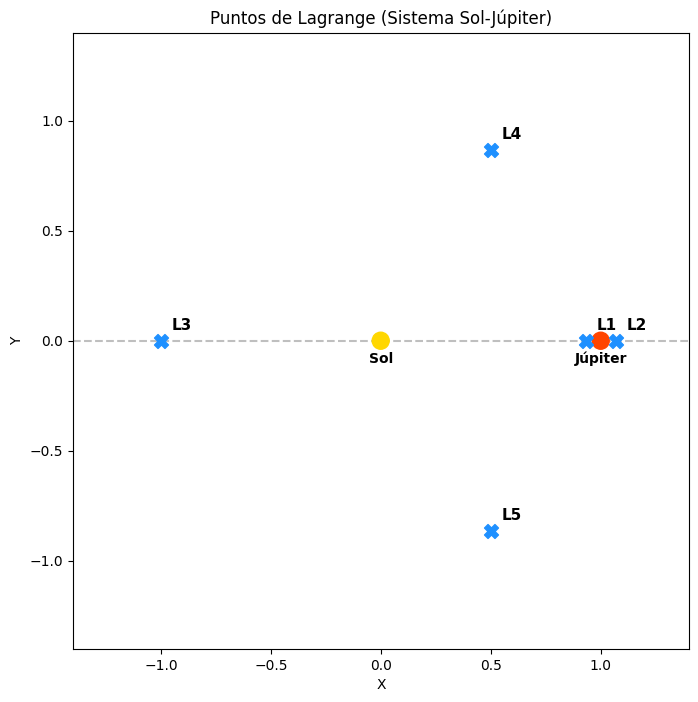

In [6]:
rho = (mu / 3) ** (1 / 3)
l_points = {
    "L1": (x2 - rho, 0),
    "L2": (x2 + rho, 0),
    "L3": (-1.0 - (7 / 12) * mu, 0),
    "L4": (0.5 - mu, np.sqrt(3) / 2),
    "L5": (0.5 - mu, -np.sqrt(3) / 2),
}

plt.figure(figsize=(8, 8))

plt.scatter([x1, x2], [0, 0], color=["gold", "orangered"], s=150, zorder=5)
plt.text(x1, -0.1, "Sol", ha="center", weight="bold")
plt.text(x2, -0.1, "Júpiter", ha="center", weight="bold")

for name, (lx, ly) in l_points.items():
    plt.scatter(lx, ly, color="dodgerblue", marker="X", s=100, zorder=5)
    plt.text(lx + 0.05, ly + 0.05, name, weight="bold", fontsize=11)

plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.xlim(-1.4, 1.4)
plt.ylim(-1.4, 1.4)
plt.gca().set_aspect("equal")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Puntos de Lagrange (Sistema Sol-Júpiter)")
plt.show()